# Citi Bike 2024: Demand Analysis

Where, when and in what weather do New Yorkers ride Citi Bike? This notebook loads every 2024 trip, counts arrivals and departures at each station in 30-minute windows, adds weather and calendar features, and explores demand by station, neighborhood, season and weather.

**Before running:** put the 2024 trip CSVs from [Citi Bike System Data](https://citibikenyc.com/system-data) in `data/trips/` (see the README). Figures used in the README are saved to `figures/`.

| Section | What it does |
|---|---|
| 1. Load and clean trips | Combine the monthly files, parse timestamps, drop incomplete rides |
| 2. Station traffic | Arrivals, departures and net traffic per station per 30 minutes |
| 3. Weather and calendar | Hourly Central Park weather, holidays, weekends, seasons |
| 4. Stations and neighborhoods | Per-station statistics, matched to NYC neighborhoods and boroughs |
| 5. Busiest and quietest stations | Stations worth a closer look |
| 6. Demand vs. variance | How volatile busy stations are |
| 7. Seasonality and weather | Citywide rides by month, day, temperature and rain |
| 8. Maps and an event | Where demand concentrates; arrivals before a Knicks game vs. other Fridays |

**Two ways of counting, used throughout:**
- *Station traffic* = rides in + out: rides starting **or** ending at a station (Sections 4–6 and the demand maps in Section 8). A ride counts once at each end. Charts label it "Avg Rides In + Out per 30min".
- *Citywide rides* = rides **started** in a time window (Section 7). Each ride counts once.

In [1]:
import pandas as pd 
import numpy as np
import time 
import glob
import re
from datetime import datetime
import dateutil 
import holidays
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load and clean trips
All 2024 trip files are combined. Ride ids are normalized, timestamps are parsed, and rides without a start or end station, or recorded at only one end, are dropped.

In [2]:
#Loading raw data into the notebook

csv_files = glob.glob("data/trips/**/*.csv", recursive=True)
dfs_2024 = [pd.read_csv(file, low_memory = False) for  file in csv_files]
df = pd.concat(dfs_2024, ignore_index= True)


In [3]:
#Preliminary data exploration

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44303209 entries, 0 to 44303208
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             object 
 1   rideable_type       object 
 2   started_at          object 
 3   ended_at            object 
 4   start_station_name  object 
 5   start_station_id    object 
 6   end_station_name    object 
 7   end_station_id      object 
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       object 
dtypes: float64(4), object(9)
memory usage: 4.3+ GB


In [4]:
df.describe()

,start_lat,start_lng,end_lat,end_lng
count,4.427337e+07,4.427337e+07,4.418090e+07,4.418090e+07
mean,4.073801e+01,-7.397144e+01,4.073770e+01,-7.397125e+01
std,4.088326e-02,2.900913e-02,9.159561e-02,1.516929e-01
min,4.063338e+01,-7.407196e+01,0.000000e+00,-7.408670e+01
25%,4.071311e+01,-7.399194e+01,4.071308e+01,-7.399203e+01
50%,4.073705e+01,-7.397907e+01,4.073653e+01,-7.397929e+01
75%,4.076144e+01,-7.395485e+01,4.076123e+01,-7.395487e+01
max,4.088630e+01,-7.384672e+01,4.088630e+01,0.000000e+00


In [5]:
#Ensuring all rides are of the same type

df['ride_id'] = df['ride_id'].astype(str).str.strip().str.lower()
df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,c40e88bb937bdc15,electric_bike,2024-09-26 09:06:40.740,2024-09-26 09:27:55.009,Columbia St & Degraw St,4422.04,6 Ave & Canal St,5500.07,40.685930,-74.002424,40.722438,-74.005664,casual
1,f9db9fb8df1b9698,electric_bike,2024-09-15 16:36:01.749,2024-09-15 16:50:41.891,Kent Ave & Grand St,5388.01,Pike St & E Broadway,5270.05,40.716425,-73.965940,40.714067,-73.992939,casual
2,2c876366cd11d036,electric_bike,2024-09-24 22:44:19.582,2024-09-24 22:59:35.506,W 67 St & Broadway,7116.04,Central Park North & Adam Clayton Powell Blvd,7617.07,40.774925,-73.982666,40.799484,-73.955613,casual
3,d639068ac8d3de4d,classic_bike,2024-09-16 16:39:05.447,2024-09-16 17:02:05.830,Madison Ave & E 82 St,7188.13,Central Park North & Adam Clayton Powell Blvd,7617.07,40.778131,-73.960694,40.799484,-73.955613,casual
4,7c1b06cfc9849b71,electric_bike,2024-09-30 15:45:18.183,2024-09-30 15:46:42.613,Lafayette Ave & St James Pl,4494.04,Willoughby Ave & Hall St,4611.03,40.688515,-73.964763,40.691960,-73.965369,casual


In [6]:
#Checking for duplicate rides
assert not df['ride_id'].duplicated().any(), "duplicate ride ids"

In [7]:
#Creating Dataframes for enters and exits

df_exits = df[['ride_id', 'started_at', 'start_station_name']].copy()
df_enter = df[['ride_id', 'ended_at', 'end_station_name']].copy()

In [8]:
#Fixing the dates in order to convert to datetime

exits_count = df_exits.shape[0]
enter_count = df_enter.shape[0]
print(f"before to datetime ride number for exits: {exits_count}" )
print(f"before to datetime ride number for arrival: {enter_count}" )

#STRIPPING THE TIMES TO CONVERT TO DATETIME

#Normalize & strip invisibles for exits
df_exits['started_at'] = (
    df_exits['started_at']
    .astype(str).str.strip()
    .str.replace('\u00A0', ' ', regex=False)
    .str.replace('\u200B', '',  regex=False)
)

#Crop anything past 19 chars
df_exits['started_at'] = df_exits['started_at'].str.replace(
    r'(^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}).*$', 
    r'\1', 
    regex=True
)
df_enter['ended_at'] = (
    df_enter['ended_at']
    .astype(str).str.strip()
    .str.replace('\u00A0', ' ', regex=False)
    .str.replace('\u200B', '',  regex=False)
    .str.replace(
        r'(^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}).*$', 
        r'\1', 
        regex=True
    )
)

#Parse with explicit format and convert dates to formal datetime index

df_exits['started_at'] = pd.to_datetime(
    df_exits['started_at'], 
    format='%Y-%m-%d %H:%M:%S', 
    errors='coerce'
)

df_enter['ended_at'] = pd.to_datetime(
    df_enter['ended_at'], 
    format='%Y-%m-%d %H:%M:%S', 
    errors='coerce'
)

print(f"after strip and datetime exits: {df_exits.shape[0]}")
print(f"after strip and datetime enter: {df_enter.shape[0]}")

#Verify that there aren't any NAT
print("Failed exits:", df_exits['started_at'].isna().sum())
print("Failed enters:", df_enter['ended_at'].isna().sum())

before to datetime ride number for exits: 44303209
before to datetime ride number for arrival: 44303209


after strip and datetime exits: 44303209
after strip and datetime enter: 44303209
Failed exits: 0
Failed enters: 0


In [9]:
# DROPS NAT IF IT EXISTS AND SETS DATETIME INDEX
df_exits = df_exits.dropna(subset=['started_at'])
df_enter = df_enter.dropna(subset=['ended_at'])

df_exits = df_exits.set_index('started_at')
df_enter = df_enter.set_index('ended_at')

In [10]:
#Printing and dropping NAN values in both departure and arrival dataframes

print(f"count for NAN values in start station names: {df_exits['start_station_name'].isna().sum()}")
print(f"count for NAN values in end station names: {df_enter['end_station_name'].isna().sum()}")

df_exits = df_exits.dropna(subset='start_station_name')
df_enter = df_enter.dropna(subset='end_station_name')

count for NAN values in start station names: 29835
count for NAN values in end station names: 114545


In [11]:
# DROP ANY RIDES THAT AREN'T PRESENT IN BOTH DATAFRAMES

df_exits = df_exits[df_exits['ride_id'].isin(df_enter['ride_id'])]
df_enter = df_enter[df_enter['ride_id'].isin(df_exits['ride_id'])]

print(df_exits.shape[0])
print(df_enter.shape[0])

44173378
44173378


## 2. Station traffic: arrivals, departures and net traffic
Rides are counted per station in 30-minute windows: departures (`df_exits_final`) and arrivals (`df_enter_final`), one column per station. **Net traffic** = arrivals − departures: positive means the station is filling up, negative means it is emptying.

In [12]:
#Grouping data by stations to show number of rides per station at each time

print(f"number of rows without station name exits: {df_exits['start_station_name'].isna().sum()}")
print(f"number of rows without station name enter: {df_enter['end_station_name'].isna().sum()}")

df_exits = df_exits.groupby('start_station_name').resample('30min')['ride_id'].count()
df_enter = df_enter.groupby('end_station_name').resample('30min')['ride_id'].count()


print(f"after resampling and grouping by stations exits: {df_exits.shape[0]}")
print(f"after resampling and grouping by stations enter: {df_enter.shape[0]}")

number of rows without station name exits: 0
number of rows without station name enter: 0


after resampling and grouping by stations exits: 37558550
after resampling and grouping by stations enter: 38437665


In [13]:
#Unstacking dataframe making stations as columns so it is easier to analyze

df_exits_final = df_exits.unstack(level='start_station_name', fill_value=0)
df_exits_final.head(30)

start_station_name,1 Ave & E 110 St,1 Ave & E 118 St,1 Ave & E 16 St,1 Ave & E 18 St,1 Ave & E 30 St,1 Ave & E 38 St,1 Ave & E 39 St,1 Ave & E 42 St,1 Ave & E 44 St,1 Ave & E 6 St,...,Woodward Ave & Harman St,Woodward Ave & Starr St,Wyckoff Ave & Cooper Ave,Wyckoff Ave & Gates Ave,Wyckoff Ave & Jefferson St,Wyckoff Ave & Stanhope St,Wyckoff St & 3 Ave,Wythe Ave & Metropolitan Ave,Wythe Ave & N 13 St,Yankee Ferry Terminal
started_at,,,,,,,,,,,,,,,,,,,,,
2023-12-31 13:30:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 14:00:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 14:30:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 15:00:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 15:30:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 16:00:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 16:30:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 17:00:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023-12-31 17:30:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
#Unstacking dataframe making stations as columns so it is easier to analyze

df_enter_final = df_enter.unstack(level='end_station_name', fill_value=0)
df_enter_final.head(30)

end_station_name,1 Ave & E 110 St,1 Ave & E 118 St,1 Ave & E 16 St,1 Ave & E 18 St,1 Ave & E 30 St,1 Ave & E 38 St,1 Ave & E 39 St,1 Ave & E 42 St,1 Ave & E 44 St,1 Ave & E 6 St,...,Woodward Ave & Starr St,Wyckoff Ave & Cooper Ave,Wyckoff Ave & Gates Ave,Wyckoff Ave & Jefferson St,Wyckoff Ave & Stanhope St,Wyckoff St & 3 Ave,Wythe Ave & Metropolitan Ave,Wythe Ave & N 13 St,Yankee Ferry Terminal,York St & Marin Blvd
ended_at,,,,,,,,,,,,,,,,,,,,,
2024-01-01 00:00:00,0,0,0,0,0,0,2,0,0,2,...,0,0,0,0,0,1,1,0,0,0
2024-01-01 00:30:00,2,0,2,2,2,0,5,0,0,5,...,0,1,1,0,0,0,0,0,0,0
2024-01-01 01:00:00,1,0,0,3,1,0,3,0,1,7,...,0,3,1,4,1,1,2,1,0,0
2024-01-01 01:30:00,0,0,2,0,1,0,0,0,1,1,...,0,0,0,3,2,0,2,0,0,0
2024-01-01 02:00:00,0,0,1,3,3,0,2,0,0,2,...,0,0,2,4,5,0,2,0,0,0
2024-01-01 02:30:00,0,0,2,3,0,0,2,0,0,1,...,0,1,1,0,1,0,3,0,0,0
2024-01-01 03:00:00,1,0,0,2,2,0,2,0,0,1,...,0,0,1,1,0,0,0,0,0,0
2024-01-01 03:30:00,1,0,0,1,2,0,2,0,0,2,...,0,0,1,0,0,0,1,0,0,0
2024-01-01 04:00:00,1,0,2,0,1,0,1,0,0,1,...,0,0,0,0,0,1,0,0,0,0


In [15]:
#Combining the dataframes ot calculate net traffic 

net_traffic_df = df_enter_final.sub(df_exits_final, fill_value=0)

#Sanity checking making sure each ride is accounted for once

print(df_enter_final.sum().sum() - df_exits_final.sum().sum())
print(net_traffic_df.sum().sum())

#Making sure that the dataframe's datetime index is based on the year 2024

net_traffic_df = net_traffic_df[net_traffic_df.index.year == 2024]


0
0.0


In [16]:
#Sanity checking net traffic dataframe
print(net_traffic_df.shape[0])
net_traffic_df.head(30)

17568


,1 Ave & E 110 St,1 Ave & E 118 St,1 Ave & E 16 St,1 Ave & E 18 St,1 Ave & E 30 St,1 Ave & E 38 St,1 Ave & E 39 St,1 Ave & E 42 St,1 Ave & E 44 St,1 Ave & E 6 St,...,Woodward Ave & Starr St,Wyckoff Ave & Cooper Ave,Wyckoff Ave & Gates Ave,Wyckoff Ave & Jefferson St,Wyckoff Ave & Stanhope St,Wyckoff St & 3 Ave,Wythe Ave & Metropolitan Ave,Wythe Ave & N 13 St,Yankee Ferry Terminal,York St & Marin Blvd
2024-01-01 00:00:00,0.0,0.0,0.0,0.0,-5.0,0.0,2.0,0.0,0.0,-1.0,...,0.0,0.0,-1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2024-01-01 00:30:00,2.0,0.0,-1.0,1.0,2.0,0.0,5.0,0.0,-1.0,3.0,...,0.0,1.0,-1.0,-1.0,-2.0,-1.0,-2.0,0.0,0.0,0.0
2024-01-01 01:00:00,1.0,0.0,-4.0,3.0,0.0,0.0,1.0,0.0,0.0,5.0,...,0.0,3.0,-1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2024-01-01 01:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,-1.0,-1.0,1.0,-3.0,-1.0,-1.0,-2.0,0.0,0.0
2024-01-01 02:00:00,0.0,0.0,-1.0,3.0,2.0,0.0,1.0,0.0,0.0,0.0,...,0.0,-1.0,-3.0,-1.0,-2.0,0.0,-1.0,-3.0,0.0,0.0
2024-01-01 02:30:00,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,-1.0,-3.0,...,0.0,1.0,-1.0,-4.0,-1.0,0.0,2.0,0.0,0.0,0.0
2024-01-01 03:00:00,1.0,0.0,-2.0,1.0,2.0,0.0,1.0,0.0,0.0,-1.0,...,0.0,0.0,-2.0,1.0,-2.0,0.0,-1.0,-3.0,0.0,0.0
2024-01-01 03:30:00,1.0,0.0,-2.0,1.0,1.0,0.0,2.0,0.0,0.0,1.0,...,0.0,0.0,-2.0,-3.0,-1.0,0.0,0.0,0.0,0.0,0.0
2024-01-01 04:00:00,1.0,0.0,-1.0,0.0,0.0,0.0,1.0,0.0,0.0,-1.0,...,0.0,0.0,0.0,-3.0,0.0,1.0,0.0,0.0,0.0,0.0
2024-01-01 04:30:00,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,-1.0,-1.0,-1.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Weather and calendar features
Hourly weather for Central Park from Meteostat, resampled to 30 minutes. Meteostat timestamps are in **UTC** while trip times are **New York local time**, so the weather is converted to New York time before it's joined. (Without this, weather lines up with rides 4–5 hours late: 2 pm rain lands on 6–7 pm rides.) Calendar features: US holidays, weekend flag, day of week, month and season.

In [17]:
#Importing weather features
from meteostat import Hourly, Point

# Central Park coordinates
cp = Point(40.7812, -73.9665)

start = datetime(2024, 1, 1, 0)
end   = datetime(2025, 1, 1, 6)   # 6 extra hours so Dec 31 evening is still covered after the time-zone conversion below

# Fetch hourly data
weather_df = Hourly(cp, start, end).fetch()

# Meteostat timestamps are UTC; trip timestamps are New York local time. Convert so weather lines up with rides.
weather_df.index = weather_df.index.tz_localize("UTC").tz_convert("America/New_York").tz_localize(None)
weather_df = weather_df[~weather_df.index.duplicated(keep="first")]   # clocks fall back once a year and repeat 1am
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8790 entries, 2023-12-31 19:00:00 to 2025-01-01 01:00:00
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   temp    8790 non-null   Float64
 1   dwpt    8790 non-null   Float64
 2   rhum    8790 non-null   Float64
 3   prcp    8784 non-null   Float64
 4   snow    0 non-null      Float64
 5   wdir    8790 non-null   Float64
 6   wspd    8790 non-null   Float64
 7   wpgt    0 non-null      Float64
 8   pres    8790 non-null   Float64
 9   tsun    0 non-null      Float64
 10  coco    8784 non-null   Float64
dtypes: Float64(11)
memory usage: 918.5 KB


In [18]:
# Rename and slice columns while keeping temp, precipitation, and wind speed. Also creates boolean column to check if raining

weather_df = (
    weather_df.rename(columns={
        "temp": "temp_c",        # °C
        "prcp": "precip_mm",     # mm
        "wspd": "wind_speed",      # km/h
    })[["temp_c", "precip_mm", "wind_speed"]].copy()
)

precip_col = weather_df.precip_mm.resample('30min').ffill() / 2

temp_col = weather_df.temp_c.resample('30min').interpolate('time')

wind_col = weather_df.wind_speed.resample('30min').ffill()

weather_df = pd.concat([precip_col, temp_col, wind_col], axis=1)

weather_df["is_raining"] = (weather_df["precip_mm"].fillna(0) > 0).astype(int)

weather_df = weather_df.loc["2024-01-01":"2024-12-31 23:30"]

weather_df['temp_f'] = weather_df['temp_c'] * 9/5 + 32

weather_df.drop('temp_c', axis=1, inplace=True)

# Number of 30-minute rows (should be 17,568 = 366 days x 48)
print(weather_df.shape[0])

17568


In [19]:
#Creating 'dates' column that represents US National Holidays 

dates = pd.date_range('2024-01-01 00:00', '2024-12-31 23:30', freq="30min")
dates_df = dates.to_series().dt.date.isin(holidays.US(years=2024))
dates_df.shape[0]

17568

In [20]:
#Adding is_weekend column to show if day is weekend or not

is_weekend_col = pd.Series(net_traffic_df.index.dayofweek >= 5, index=net_traffic_df.index, name= 'is_weekend')
day_col = pd.Series(net_traffic_df.index.dayofweek, index=net_traffic_df.index, name='day of week')
month_col = pd.Series(net_traffic_df.index.month, index=net_traffic_df.index, name='month')
print(is_weekend_col.shape[0])
print(day_col.shape[0])
print(month_col.shape[0])

17568
17568
17568


In [21]:
# #Adding Day of Week and Month 

days_dates_df = pd.concat([is_weekend_col, day_col, month_col], axis=1)
print(f"days and dates len: {days_dates_df.shape[0]}")
print(f"weather len: {weather_df.shape[0]}")
print(f"holidays len: {dates_df.shape[0]}")

days and dates len: 17568
weather len: 17568
holidays len: 17568


In [22]:
#Joining weather and national holiday mask to traffic dataframe

dates_df.name = 'holidays'
final_df = net_traffic_df.join(weather_df, how='left').join(dates_df, how='left').join(days_dates_df, how='left')

In [23]:
#Checking if same length as traffic dataframe and also ensuring there is no NANs

print(final_df['holidays'].isna().sum())

0


In [24]:
#Sanity check ensuring the number of entries for holidays dates are correct
final_df[final_df['holidays'] == True].shape[0]

528

In [25]:
#Creating function that maps the date to a corresponding season in order to see seasonality features

def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'
season_col = pd.Series([get_season(m) for m in final_df.index.month], index= final_df.index, name='season')
final_df = final_df.join(season_col, how='left')

**Sanity checks.** Every ride is counted once as an arrival and once as a departure, so net traffic should average about zero. The full feature table is saved to `dataframe_final.csv` (not in git; it's large).

In [26]:
final_df.to_csv('dataframe_final.csv')

In [27]:
final_df.iloc[:, :-9].stack().describe()


count    4.028342e+07
mean     9.035975e-06
std      1.773077e+00
min     -7.600000e+01
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      6.700000e+01
dtype: float64

In [28]:
final_df.iloc[:, :-9].sum(axis=1).describe()


count    17568.000000
mean         0.020719
std        209.315904
min      -1963.000000
25%        -90.000000
50%          5.000000
75%         84.000000
max       2030.000000
dtype: float64

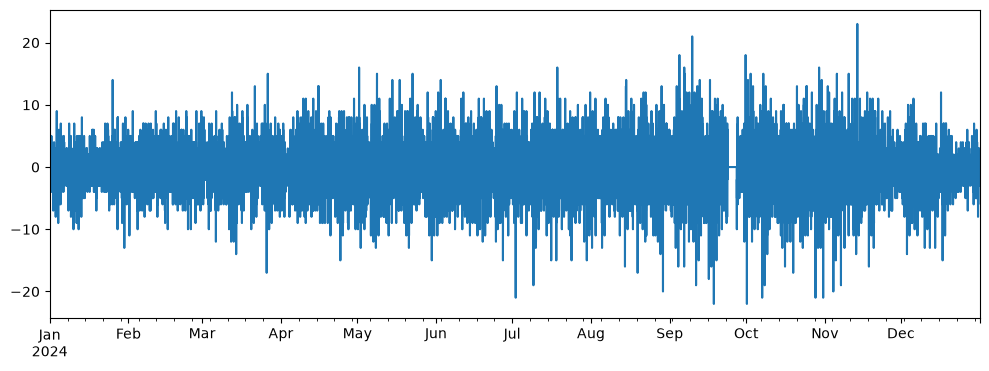

In [29]:
final_df['1 Ave & E 16 St'].plot(figsize=(12,4))
plt.show()

In [30]:
final_df.head()


,1 Ave & E 110 St,1 Ave & E 118 St,1 Ave & E 16 St,1 Ave & E 18 St,1 Ave & E 30 St,1 Ave & E 38 St,1 Ave & E 39 St,1 Ave & E 42 St,1 Ave & E 44 St,1 Ave & E 6 St,...,York St & Marin Blvd,precip_mm,wind_speed,is_raining,temp_f,holidays,is_weekend,day of week,month,season
2024-01-01 00:00:00,0.0,0.0,0.0,0.0,-5.0,0.0,2.0,0.0,0.0,-1.0,...,0.0,0.05,11.0,1,42.8,True,False,0,1,Winter
2024-01-01 00:30:00,2.0,0.0,-1.0,1.0,2.0,0.0,5.0,0.0,-1.0,3.0,...,0.0,0.05,11.0,1,42.8,True,False,0,1,Winter
2024-01-01 01:00:00,1.0,0.0,-4.0,3.0,0.0,0.0,1.0,0.0,0.0,5.0,...,0.0,0.0,7.0,0,42.8,True,False,0,1,Winter
2024-01-01 01:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,7.0,0,41.9,True,False,0,1,Winter
2024-01-01 02:00:00,0.0,0.0,-1.0,3.0,2.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,6.8,0,41.0,True,False,0,1,Winter


## 4. Station statistics and neighborhoods
For each station: average and variance of its traffic per 30 minutes, and its 2024 total. Stations are matched to NYC Neighborhood Tabulation Areas (NTAs) and boroughs by location.

In [31]:
total_traffic_df = df_enter_final.add(df_exits_final, fill_value=0)
total_traffic_df = total_traffic_df[total_traffic_df.index.year == 2024]

#Creating a dataframe that represents the statistics for each station

station_stats = pd.DataFrame({
    'station': total_traffic_df.columns,
    'avg_rides_30min': total_traffic_df.mean(),
    'variance': total_traffic_df.var(),
    'total_rides': total_traffic_df.sum()
}).reset_index(drop=True)

In [32]:
#Getting station latitude and longitude coordinates from raw data
# One location per station: the median of its trip start coordinates (a few stations moved during the year)
stations_cord_df = (
    df.groupby('start_station_name')[['start_lat', 'start_lng']]
    .median()
    .reset_index()
    .rename(columns={'start_station_name': 'station', 'start_lat': 'lat', 'start_lng': 'lon'})
)

print(stations_cord_df.head())
print(stations_cord_df.shape[0])

del df   # the full trip table isn't needed after this (frees several GB)

            station        lat        lon
0  1 Ave & E 110 St  40.792327 -73.938300
1  1 Ave & E 118 St  40.797459 -73.934499
2   1 Ave & E 16 St  40.732219 -73.981656
3   1 Ave & E 18 St  40.733812 -73.980544
4   1 Ave & E 30 St  40.741444 -73.975361
2273


In [33]:
import geopandas as gpd
from shapely.geometry import Point

#Importing NTA (Neighborhood Tabulation Areas) data 

NTA = gpd.read_file('Neighborhood_NTA.geojson')
NTA = NTA[["nta2020","ntaname","boroname","geometry"]]
NTA = NTA.rename(columns={"nta2020": "NTA2020", "ntaname": "NTAName", "boroname": "BoroName"})


# Build station GeoDataFrame
stations_gdf = gpd.GeoDataFrame(
    stations_cord_df.copy(), 
    geometry=gpd.points_from_xy(stations_cord_df["lon"], stations_cord_df["lat"]),
    crs="EPSG:4326"
)

# Ensure CRS match
NTA = NTA.set_crs("EPSG:4326") if NTA.crs is None else NTA.to_crs("EPSG:4326")

# Spatial join: assign each station to an NTA
stations_with_nta = gpd.sjoin(
    stations_gdf,
    NTA[["NTA2020", "NTAName", "BoroName", "geometry"]],
    how="left",
    predicate="intersects"
)
# Clean result
stations_with_nta = stations_with_nta[["station", "lat", "lon", "NTA2020", "NTAName", "BoroName"]]
stations_with_nta = stations_with_nta.drop_duplicates(subset='station')






In [34]:
# Stations that didn't fall inside any NYC neighborhood (Jersey City and Hoboken, which have their own Citi Bike data)
print(stations_with_nta[stations_with_nta.isna().any(axis=1)])

                                           station        lat        lon  \
44                           11 St & Washington St  40.749985 -74.027150   
55                            12 St & Sinatra Dr N  40.750604 -74.024020   
58               14 St Ferry - 14 St & Shipyard Ln  40.752961 -74.024353   
240                                4 St & Grand St  40.742258 -74.035111   
241                                4 St & River St  40.740814 -74.027406   
...                                            ...        ...        ...   
1885  South Waterfront Walkway - Sinatra Dr & 1 St  40.736982 -74.027781   
1897    Southwest Park - Jackson St & Observer Hwy  40.737551 -74.041664   
1950                    Stevens - River Ter & 6 St  40.743133 -74.026989   
2204                                 Washington St  40.724294 -74.035483   
2247                            Willow Ave & 12 St  40.751867 -74.030377   

     NTA2020 NTAName BoroName  
44       NaN     NaN      NaN  
55       NaN     NaN   

In [35]:
#Combining station statistics along with neighborhood and borough data

station_stats = station_stats.merge(
    stations_with_nta[["station", "NTAName", "BoroName"]],
    on="station",
    how="left"
)


In [36]:
# Stations without a neighborhood after the merge (the Jersey City/Hoboken stations above, plus stations that never
# appear as a trip start and so have no coordinates), then the full table
print(station_stats[station_stats.isna().any(axis=1)])
print(station_stats)

                                station  avg_rides_30min  variance  \
44                11 St & Washington St         0.006318  0.007759   
55                 12 St & Sinatra Dr N         0.011157  0.013993   
58    14 St Ferry - 14 St & Shipyard Ln         0.027379  0.048035   
79                      2 St & Park Ave         0.001366  0.001478   
241                     4 St & Grand St         0.000455  0.000455   
...                                 ...              ...       ...   
2028                     Van Vorst Park         0.002220  0.002215   
2206                          Warren St         0.003188  0.003178   
2223                      Washington St         0.001252  0.001365   
2266                 Willow Ave & 12 St         0.002561  0.002669   
2292               York St & Marin Blvd         0.000683  0.000910   

      total_rides NTAName BoroName  
44          111.0     NaN      NaN  
55          196.0     NaN      NaN  
58          481.0     NaN      NaN  
79         

## 5. Busiest and quietest stations
The 20 stations with the most traffic and the 20 with the least: candidates for a closer look. They're ranked only among **NYC stations with rides in every month of 2024**. Jersey City and Hoboken stations appear in this data only through the occasional cross-river ride (they have their own Citi Bike data), and stations that opened, closed or were renamed during the year have months of zeros, so either would otherwise look artificially quiet.

In [37]:
# Rank only NYC stations (inside an NYC neighborhood) that had rides in every month of 2024
months_active = (total_traffic_df.resample('ME').sum() > 0).sum()
station_stats['months_active'] = station_stats['station'].map(months_active)
ranked = station_stats[station_stats['NTAName'].notna() & (station_stats['months_active'] == 12)]
print(f"{len(ranked):,} of {len(station_stats):,} stations are in NYC and had rides in every month of 2024")

# Expansion candidates = high demand stations
expansion_candidates = ranked.sort_values("avg_rides_30min", ascending=False).head(20)

# Consolidation candidates = consistently low demand stations
consolidation_candidates = ranked.sort_values("avg_rides_30min", ascending=True).head(20)

expansion_candidates.head(20)

2,013 of 2,293 stations are in NYC and had rides in every month of 2024


,station,avg_rides_30min,variance,total_rides,NTAName,BoroName,months_active
2099,W 21 St & 6 Ave,18.623577,309.952850,327179.0,Chelsea-Hudson Yards,Manhattan,12
467,8 Ave & W 31 St,16.061418,221.938107,282167.0,Chelsea-Hudson Yards,Manhattan,12
2014,University Pl & E 14 St,16.058345,239.463949,282113.0,Greenwich Village,Manhattan,12
2241,West St & Chambers St,15.527038,358.100026,272779.0,Financial District-Battery Park City,Manhattan,12
704,Broadway & W 58 St,15.385018,250.523011,270284.0,Midtown-Times Square,Manhattan,12
1477,Lafayette St & E 8 St,15.326218,250.912930,269251.0,Greenwich Village,Manhattan,12
2119,W 31 St & 7 Ave,14.599898,197.749569,256491.0,Midtown South-Flatiron-Union Square,Manhattan,12
666,Broadway & E 14 St,14.509847,195.529589,254909.0,Greenwich Village,Manhattan,12
40,11 Ave & W 41 St,14.492828,193.969437,254610.0,Chelsea-Hudson Yards,Manhattan,12
694,Broadway & W 25 St,13.784324,217.777982,242163.0,Midtown South-Flatiron-Union Square,Manhattan,12


In [38]:
consolidation_candidates.head(20)

,station,avg_rides_30min,variance,total_rides,NTAName,BoroName,months_active
1755,Pier 40 X2,0.034779,0.048258,611.0,West Village,Manhattan,12
420,65 St & 2 Ave,0.057377,0.099400,1008.0,Sunset Park (West),Brooklyn,12
1869,Sedgwick Ave & Hall of Fame Terrace,0.057548,0.074049,1011.0,University Heights (South)-Morris Heights,Bronx,12
487,9 Ave & W 204 St,0.058345,0.099004,1025.0,Inwood,Manhattan,12
1219,Faile St & Garrison Ave,0.063638,0.104563,1118.0,Hunts Point,Bronx,12
994,E 134 St & Walnut Ave,0.069103,0.112831,1214.0,Mott Haven-Port Morris,Bronx,12
1111,E 48 St & Tilden Ave,0.079007,0.117171,1388.0,East Flatbush-Rugby,Brooklyn,12
1989,Tibbett Ave & W 234 St,0.079064,0.119496,1389.0,Kingsbridge-Marble Hill,Bronx,12
413,64 St & 3 Ave,0.079235,0.115541,1392.0,Sunset Park (West),Brooklyn,12
488,9 Ave & W 219 St,0.079235,0.105864,1392.0,Inwood,Manhattan,12


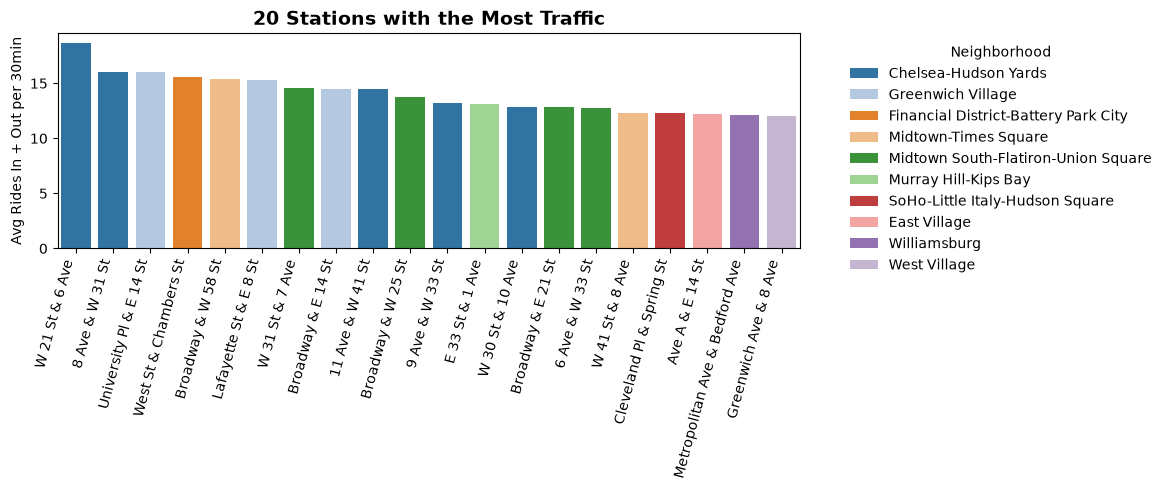

In [39]:
plt.figure(figsize=(12,5))
sns.barplot(
    data=expansion_candidates,
    x="station", 
    y="avg_rides_30min",
    hue="NTAName",             # color by neighborhood
    dodge=False,               # keep one bar per station
    palette="tab20"            # or "Set3", "Paired"
)
plt.title("20 Stations with the Most Traffic", fontsize=14, fontweight="bold")
plt.ylabel("Avg Rides In + Out per 30min")
plt.xlabel("")
plt.xticks(rotation=75, ha="right")  # tilt station names
plt.legend(title="Neighborhood", bbox_to_anchor=(1.05,1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

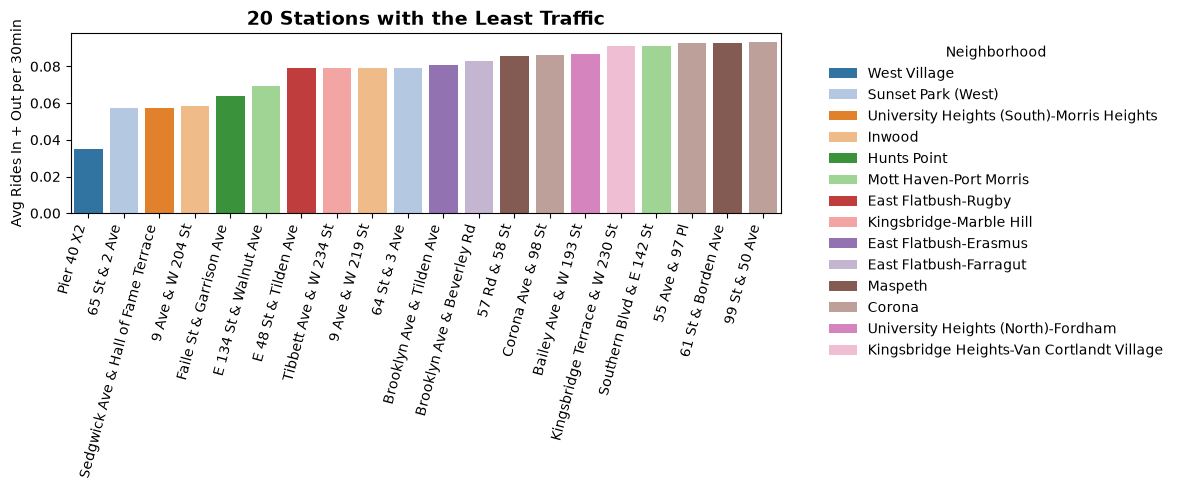

In [40]:
plt.figure(figsize=(12,5))
sns.barplot(
    data=consolidation_candidates,
    x="station", 
    y="avg_rides_30min",
    hue="NTAName",
    dodge=False,
    palette="tab20",
    order=consolidation_candidates.sort_values("avg_rides_30min")["station"]
)
plt.title("20 Stations with the Least Traffic", fontsize=14, fontweight="bold")
plt.ylabel("Avg Rides In + Out per 30min")
plt.xlabel("")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Neighborhood", bbox_to_anchor=(1.05,1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

## 6. Demand vs. variance
Busier stations are also more variable. These plots compare each station's average traffic with its variance, by borough and by neighborhood.

In [41]:
#Creating dataframes representing average rides per neighborhood and borough
station_stats_neigh_summary = station_stats.groupby('NTAName')[['avg_rides_30min','variance','total_rides']].mean().sort_values('total_rides', ascending=False).reset_index()
station_stats_boro_summary = station_stats.groupby('BoroName')[['avg_rides_30min','variance','total_rides']].mean().sort_values('total_rides', ascending=False).reset_index()

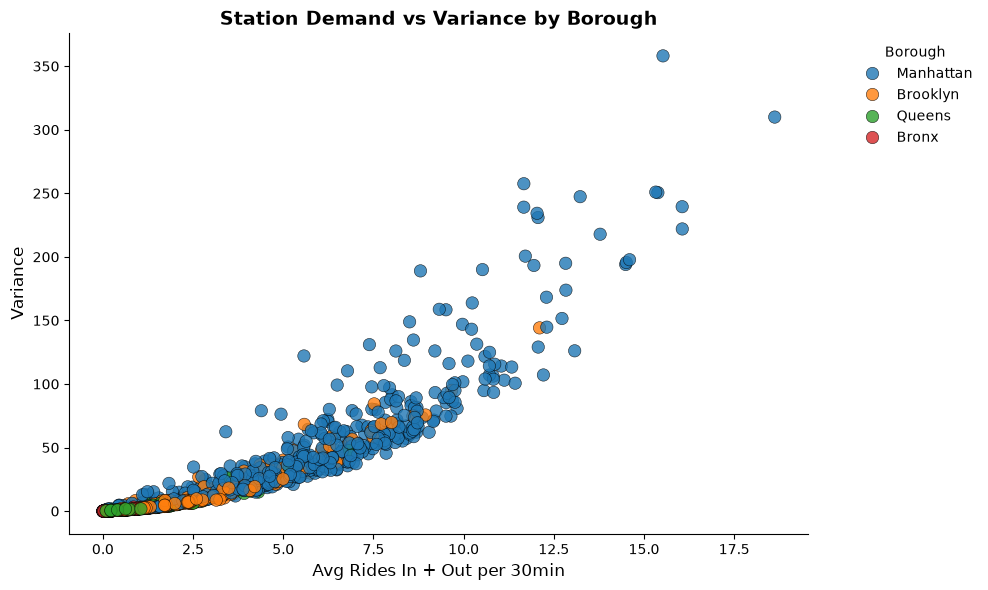

In [42]:
#Plotting Station Demand vs Variance for each borough

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=station_stats,
    x="avg_rides_30min", y="variance",
    hue="BoroName",
    palette="tab10",   
    s=80, alpha=0.8, edgecolor="black", linewidth=0.4
)
plt.title("Station Demand vs Variance by Borough", fontsize=14, fontweight="bold")
plt.xlabel("Avg Rides In + Out per 30min", fontsize=12)
plt.ylabel("Variance", fontsize=12)
sns.despine()
plt.legend(title="Borough", bbox_to_anchor=(1.05,1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()


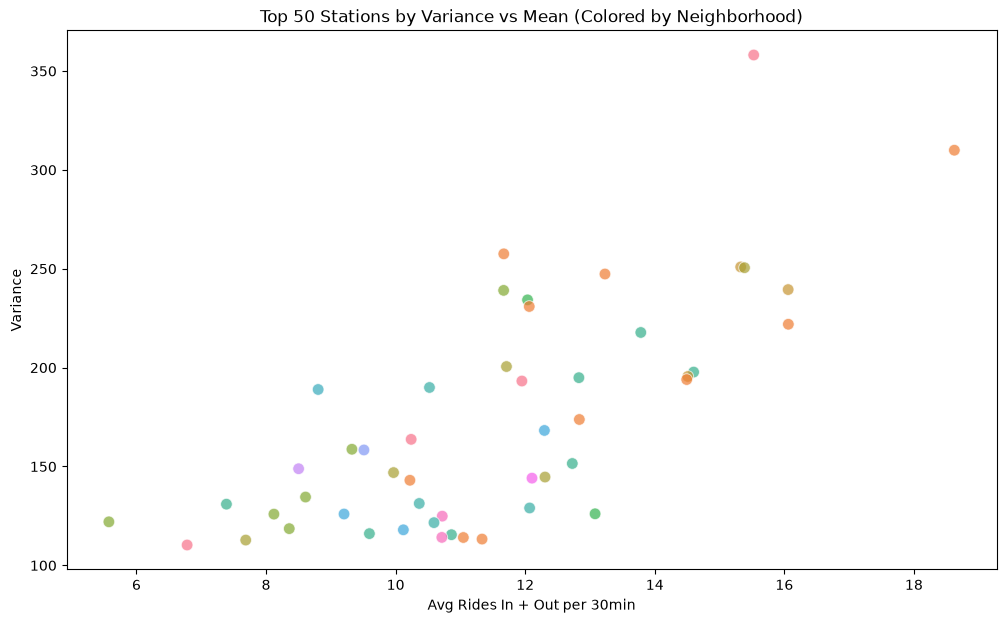

In [43]:
#Plotting variance vs mean for the top 50 stations with highest variance

top_var = station_stats.nlargest(50, "variance")

plt.figure(figsize=(12,7))
sns.scatterplot(
    data=top_var,
    x="avg_rides_30min",
    y="variance",
    hue="NTAName",          # color by neighborhood
    legend=False,           # too many neighborhoods → legend unreadable
    s=70, alpha=0.7
)
plt.title("Top 50 Stations by Variance vs Mean (Colored by Neighborhood)")
plt.xlabel("Avg Rides In + Out per 30min")
plt.ylabel("Variance")
plt.show()


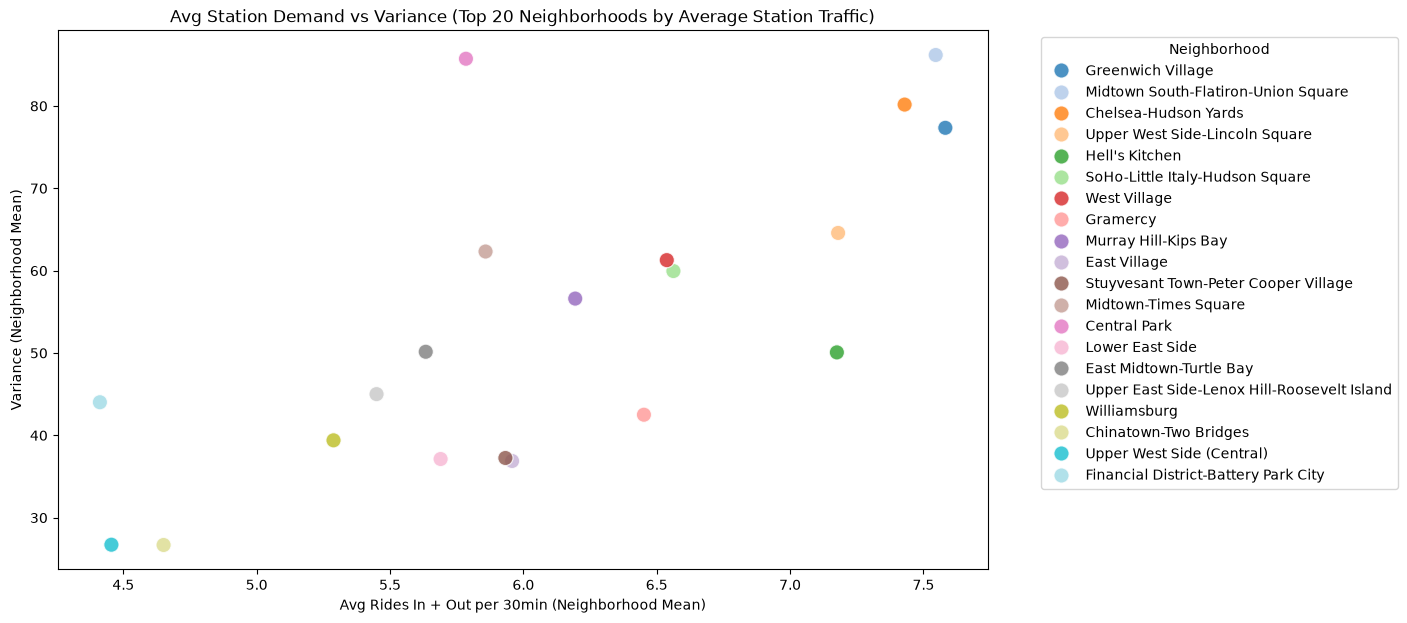

In [44]:
#Plotting the station mean vs variance by the neighborhood

plt.figure(figsize=(12,7))
sns.scatterplot(
    data=station_stats_neigh_summary.head(20),
    x="avg_rides_30min", 
    y="variance",
    hue="NTAName",
    s=120, alpha=0.8, palette="tab20"
)
plt.title("Avg Station Demand vs Variance (Top 20 Neighborhoods by Average Station Traffic)")
plt.xlabel("Avg Rides In + Out per 30min (Neighborhood Mean)")
plt.ylabel("Variance (Neighborhood Mean)")
plt.legend(title="Neighborhood", bbox_to_anchor=(1.05,1), loc="upper left")
plt.show()


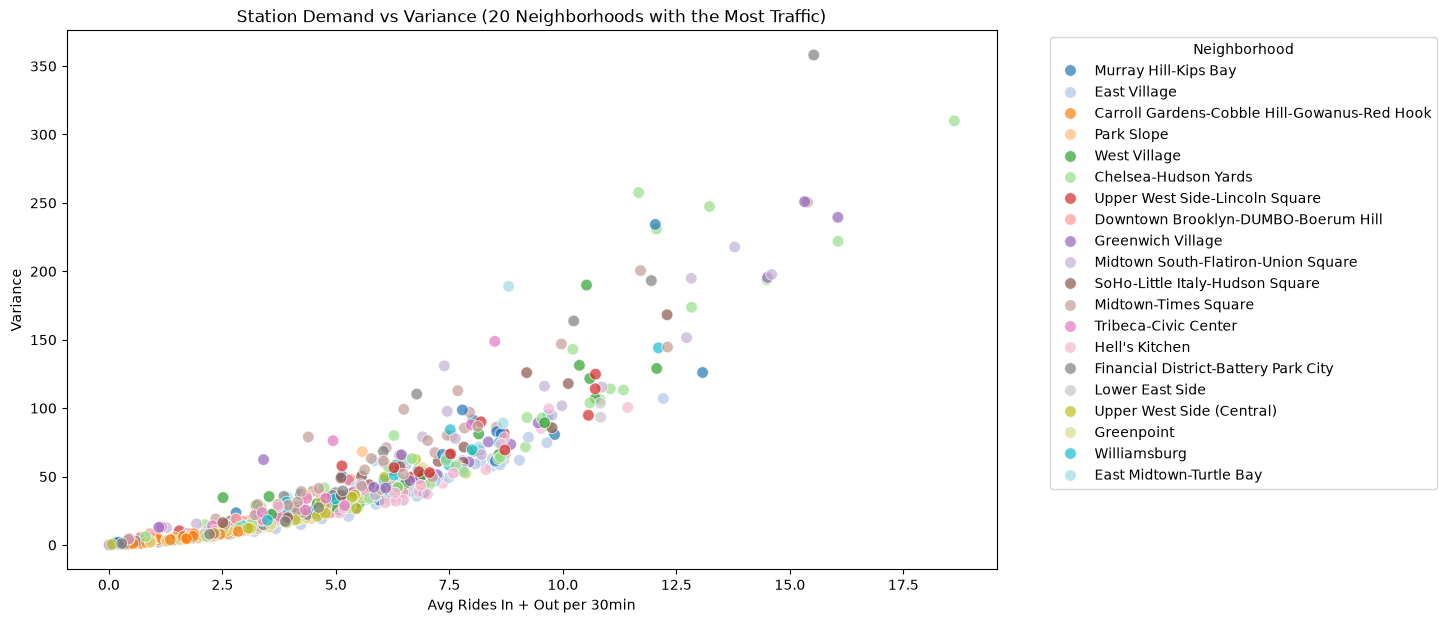

In [45]:
# Rank neighborhoods by total rides

top_neigh = (
    station_stats.groupby("NTAName")["total_rides"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
    .index
)

plot_data = station_stats[station_stats["NTAName"].isin(top_neigh)]

plt.figure(figsize=(12,7))
sns.scatterplot(
    data=plot_data,
    x="avg_rides_30min", y="variance",
    hue="NTAName",
    palette="tab20",    # 20 distinct colors, one per neighborhood
    s=70, alpha=0.7
)
plt.title("Station Demand vs Variance (20 Neighborhoods with the Most Traffic)")
plt.xlabel("Avg Rides In + Out per 30min")
plt.ylabel("Variance")
plt.legend(title="Neighborhood", bbox_to_anchor=(1.05,1), loc="upper left")
plt.show()


## 7. Seasonality and weather
Citywide rides (rides **started**, so each ride counts once) per month and per 30 minutes, broken down by month, day of week, temperature and precipitation. Precipitation is in mm per 30 minutes.

In [46]:
# Citywide rides started in each 30-minute window, with weather and calendar features
citywide = pd.concat(
    [df_exits_final[df_exits_final.index.year == 2024].sum(axis=1).reindex(dates, fill_value=0).rename('total rides'),
     weather_df, dates_df, days_dates_df, season_col],
    axis=1
)
print(f"rides in 2024: {citywide['total rides'].sum():,.0f}")
citywide.head()

rides in 2024: 44,173,014


,total rides,precip_mm,wind_speed,is_raining,temp_f,holidays,is_weekend,day of week,month,season
2024-01-01 00:00:00,743,0.05,11.0,1,42.8,True,False,0,1,Winter
2024-01-01 00:30:00,1149,0.05,11.0,1,42.8,True,False,0,1,Winter
2024-01-01 01:00:00,1151,0.0,7.0,0,42.8,True,False,0,1,Winter
2024-01-01 01:30:00,1160,0.0,7.0,0,41.9,True,False,0,1,Winter
2024-01-01 02:00:00,1071,0.0,6.8,0,41.0,True,False,0,1,Winter


In [47]:
#Creating dataframes that represent total rides per week and per month

monthly_demand = citywide['total rides'].resample('ME').sum().reset_index()
weekly_demand = citywide['total rides'].resample('W').sum().reset_index()

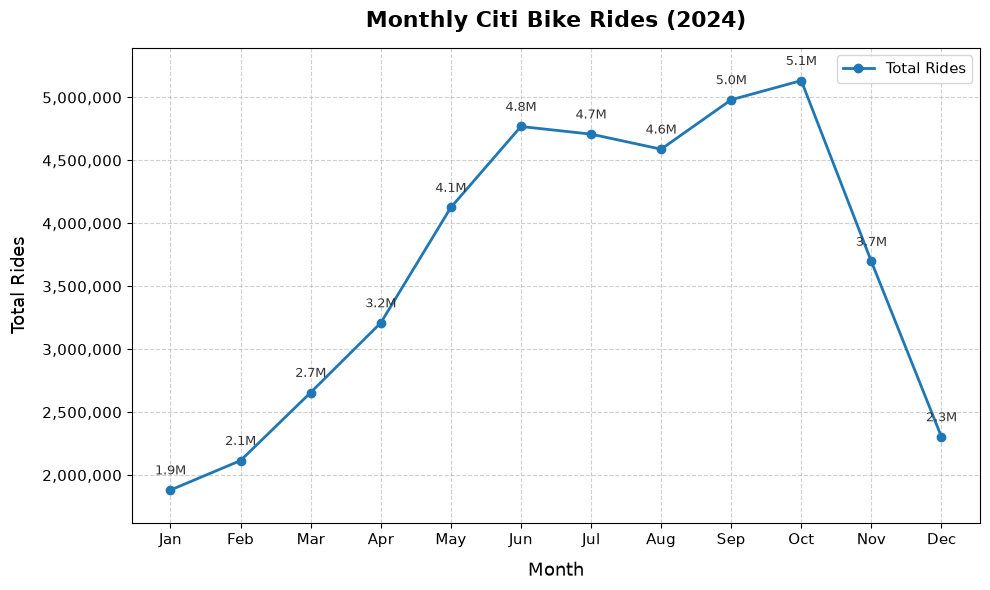

In [48]:
import matplotlib.ticker as mtick

plt.figure(figsize=(10,6))
plt.plot(
    monthly_demand['total rides'], 
    marker="o", 
    linestyle="-", 
    linewidth=2, 
    markersize=6, 
    color="#1f77b4", 
    label="Total Rides"
)


plt.title("Monthly Citi Bike Rides (2024)", fontsize=16, weight="bold", pad=15)
plt.xlabel("Month", fontsize=13, labelpad=10)
plt.ylabel("Total Rides", fontsize=13, labelpad=10)


months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
plt.xticks(ticks=range(len(months)), labels=months, fontsize=11)


plt.gca().yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))


plt.grid(True, linestyle="--", alpha=0.6)
plt.yticks(fontsize=11)


for i, val in enumerate(monthly_demand['total rides']):
    plt.text(i, val+100000, f"{val/1e6:.1f}M", ha="center", va="bottom", fontsize=9, color="#333")


plt.margins(y=0.08)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("figures/monthly_trend.png", dpi=200, bbox_inches="tight")
plt.show()


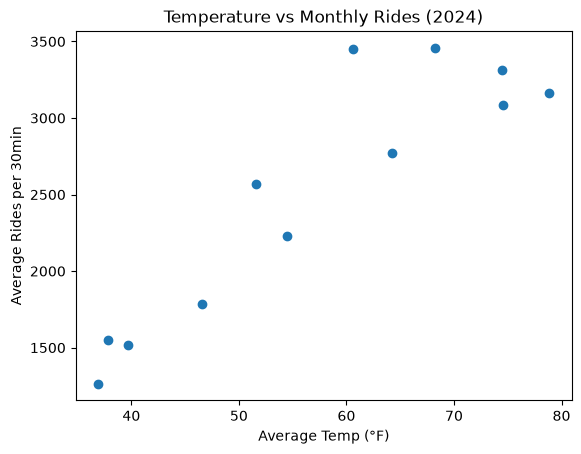

In [49]:
# Monthly averages for smoother view
weather_monthly = citywide[["total rides", "temp_f", "is_raining"]].resample("ME").mean()

plt.scatter(weather_monthly["temp_f"], weather_monthly["total rides"])
plt.title("Temperature vs Monthly Rides (2024)")
plt.xlabel("Average Temp (°F)")
plt.ylabel("Average Rides per 30min")
plt.show()

**Heatmaps.** Average citywide rides per 30 minutes for each combination. Blank cells are combinations that never occurred in 2024.

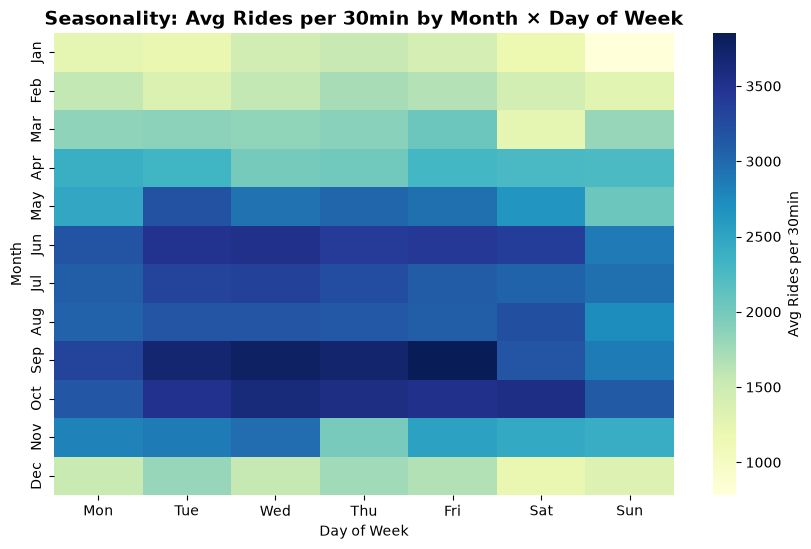

In [50]:
#Heatmap the shows which days and which months have the most traffic

heatmap_df = citywide[['total rides']].copy()
heatmap_df["month"] = heatmap_df.index.month
heatmap_df["day_of_week"] = heatmap_df.index.dayofweek

# Map days and months to names
day_map = {0:'Mon', 1:'Tue', 2:'Wed', 3:'Thu', 4:'Fri', 5:'Sat', 6:'Sun'}
month_map = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun',
             7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'}

heatmap_df["day_name"] = heatmap_df["day_of_week"].map(day_map)
heatmap_df["month_name"] = heatmap_df["month"].map(month_map)

heatmap_group = (
    heatmap_df.groupby(["month_name","day_name"])["total rides"]
    .mean()
    .unstack()
    .reindex(index=list(month_map.values()), columns=list(day_map.values()))
)

plt.figure(figsize=(10,6))
sns.heatmap(heatmap_group, cmap="YlGnBu", annot=False, cbar_kws={'label': 'Avg Rides per 30min'})
plt.title("Seasonality: Avg Rides per 30min by Month × Day of Week", fontsize=14, fontweight="bold")
plt.xlabel("Day of Week")
plt.ylabel("Month")
plt.show()

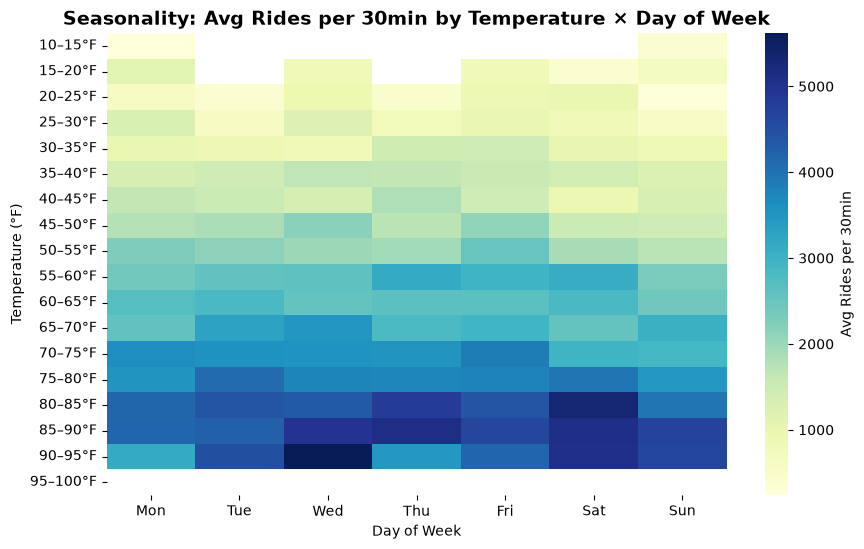

In [51]:
# Creating Heatmap of Day of Week vs Temperature

heatmap_df_temp = citywide[['temp_f']].copy()

heatmap_df_temp['day'] = heatmap_df_temp.index.dayofweek
heatmap_df_temp['total_rides'] = citywide['total rides']

# Temp bins with labels
bins = np.arange(10, 105, 5)
labels = [f"{low}–{high}°F" for low, high in zip(bins[:-1], bins[1:])]
heatmap_df_temp['temp_bin'] = pd.cut(
    heatmap_df_temp['temp_f'], 
    bins=bins,  
    labels=labels,
    right=False,
    include_lowest=True,
    ordered=True
)

# Map day numbers to names
day_map = {0:'Mon', 1:'Tue', 2:'Wed', 3:'Thu', 4:'Fri', 5:'Sat', 6:'Sun'}
heatmap_df_temp['day_name'] = heatmap_df_temp['day'].map(day_map)

heatmap_df_group = (
    heatmap_df_temp.groupby(['temp_bin','day_name'], observed=False)['total_rides']
    .mean()
    .unstack()
    .reindex(columns=['Mon','Tue','Wed','Thu','Fri','Sat','Sun']) 
    .reindex(index=labels)  
)

plt.figure(figsize=(10,6))
sns.heatmap(heatmap_df_group, cmap="YlGnBu", annot=False, cbar_kws={'label': 'Avg Rides per 30min'})
plt.title("Seasonality: Avg Rides per 30min by Temperature × Day of Week", fontsize=14, fontweight="bold")
plt.xlabel("Day of Week")
plt.ylabel("Temperature (°F)")
plt.show()


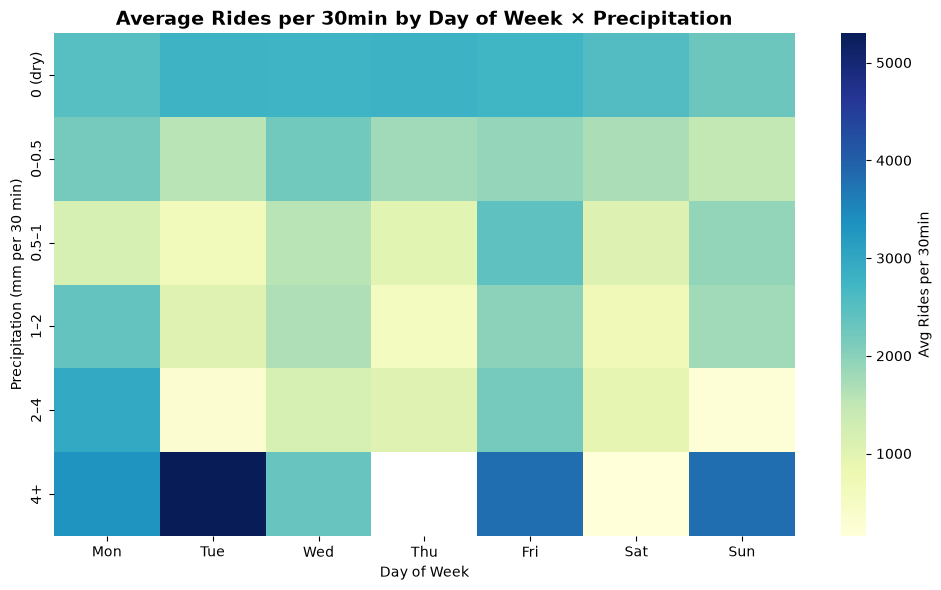

In [52]:
# Creating a heatmap of total rides for day of week vs precipitation

heatmap_df_rain_day = citywide[['precip_mm']].copy()

# Add day of week (0=Mon, 6=Sun)
heatmap_df_rain_day['day'] = heatmap_df_rain_day.index.dayofweek
day_map = {0:'Mon', 1:'Tue', 2:'Wed', 3:'Thu', 4:'Fri', 5:'Sat', 6:'Sun'}
heatmap_df_rain_day['day_name'] = heatmap_df_rain_day['day'].map(day_map)

# Compute total rides per timestamp
heatmap_df_rain_day['total_rides'] = citywide['total rides']

# --- Precipitation bins (mm per 30 min); dry half-hours get their own bin ---
precip_bins = [-np.inf, 0, 0.5, 1, 2, 4, np.inf]
precip_labels = ["0 (dry)", "0–0.5", "0.5–1", "1–2", "2–4", "4+"]

heatmap_df_rain_day['precip_bin'] = pd.cut(heatmap_df_rain_day['precip_mm'], bins=precip_bins, labels=precip_labels, right=True, ordered=True)

# Group and pivot
heatmap_df_group = (
    heatmap_df_rain_day
    .groupby(['precip_bin','day_name'], observed=False)['total_rides']
    .mean()
    .unstack()
    .reindex(index=precip_labels, columns=['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
)

# Plot heatmap
plt.figure(figsize=(10,6))
sns.heatmap(heatmap_df_group, cmap="YlGnBu", cbar_kws={'label': 'Avg Rides per 30min'})
plt.title("Average Rides per 30min by Day of Week × Precipitation", fontsize=14, fontweight="bold")
plt.xlabel("Day of Week")
plt.ylabel("Precipitation (mm per 30 min)")
plt.tight_layout()
plt.show()


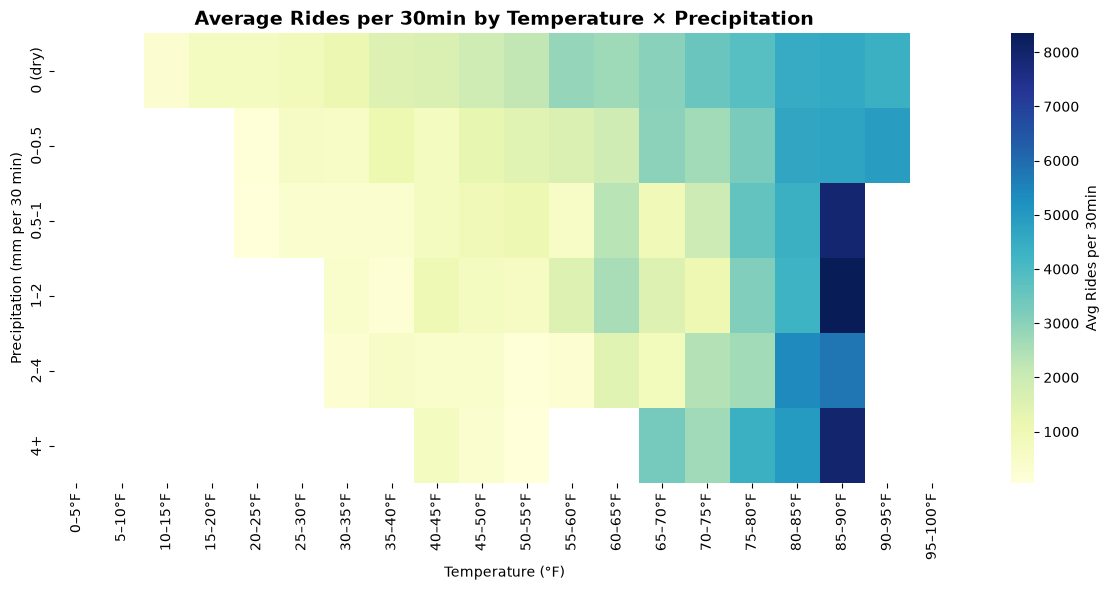

temp_bin,10–15°F,15–20°F,20–25°F,25–30°F,30–35°F,35–40°F,40–45°F,45–50°F,50–55°F,55–60°F,60–65°F,65–70°F,70–75°F,75–80°F,80–85°F,85–90°F,90–95°F
precip_bin,,,,,,,,,,,,,,,,,
0 (dry),23,93,164,388,846,1327,1302,1159,1369,1193,1595,1761,1538,1522,809,339,58
0–0.5,0,0,2,39,61,168,185,163,204,95,133,105,92,127,56,29,3
0.5–1,0,0,1,3,14,26,48,48,52,18,8,22,20,26,11,3,0
1–2,0,0,0,0,2,11,27,44,21,8,11,27,19,11,7,2,0
2–4,0,0,0,0,6,8,6,24,8,6,3,8,4,9,5,1,0
4+,0,0,0,0,0,0,2,8,8,0,0,2,2,3,3,2,0


In [53]:
# Creating a heatmap of total rides for temperature vs the amount it rains

heatmap_df_rain = citywide[['temp_f', 'precip_mm']].copy()
heatmap_df_rain['total_rides'] = citywide['total rides']

# --- Temperature bins with labels ---
bins = np.arange(0, 105, 5)
labels = [f"{low}–{high}°F" for low, high in zip(bins[:-1], bins[1:])]

heatmap_df_rain["temp_bin"] = pd.cut(
    heatmap_df_rain["temp_f"], 
    bins=bins, 
    labels=labels,  
    include_lowest=True,
    right=False,
    ordered=True
)

# --- Precipitation bins (mm per 30 min); dry half-hours get their own bin ---
precip_bins = [-np.inf, 0, 0.5, 1, 2, 4, np.inf]
precip_labels = ["0 (dry)", "0–0.5", "0.5–1", "1–2", "2–4", "4+"]

heatmap_df_rain['precip_bin'] = pd.cut(heatmap_df_rain['precip_mm'], bins=precip_bins, labels=precip_labels, right=True, ordered=True)

heatmap_df_group = (
    heatmap_df_rain
    .groupby(['precip_bin','temp_bin'], observed=False)['total_rides']
    .mean()
    .unstack()
    .reindex(index=precip_labels, columns=labels)
)

plt.figure(figsize=(12,6))
sns.heatmap(heatmap_df_group, cmap="YlGnBu", cbar_kws={'label': 'Avg Rides per 30min'})
plt.title("Average Rides per 30min by Temperature × Precipitation", fontsize=14, fontweight="bold")
plt.xlabel("Temperature (°F)")
plt.ylabel("Precipitation (mm per 30 min)")
plt.tight_layout()
plt.savefig("figures/temp_precip_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

# Number of half-hours behind each cell (cells with only a few are noisy)
precip_counts = heatmap_df_rain.groupby(['precip_bin', 'temp_bin'], observed=False).size().unstack()
precip_counts.loc[:, precip_counts.sum() > 0]


## 8. Maps and an event
A static station demand map (used in the README), an interactive version saved to `station_demand_map.html` (open it in a browser), and arrivals near Madison Square Garden in the 90 minutes before a Knicks game (Bucks at Knicks, Friday Nov 8, 2024, 7:30 PM tip-off), compared with other Friday evenings.

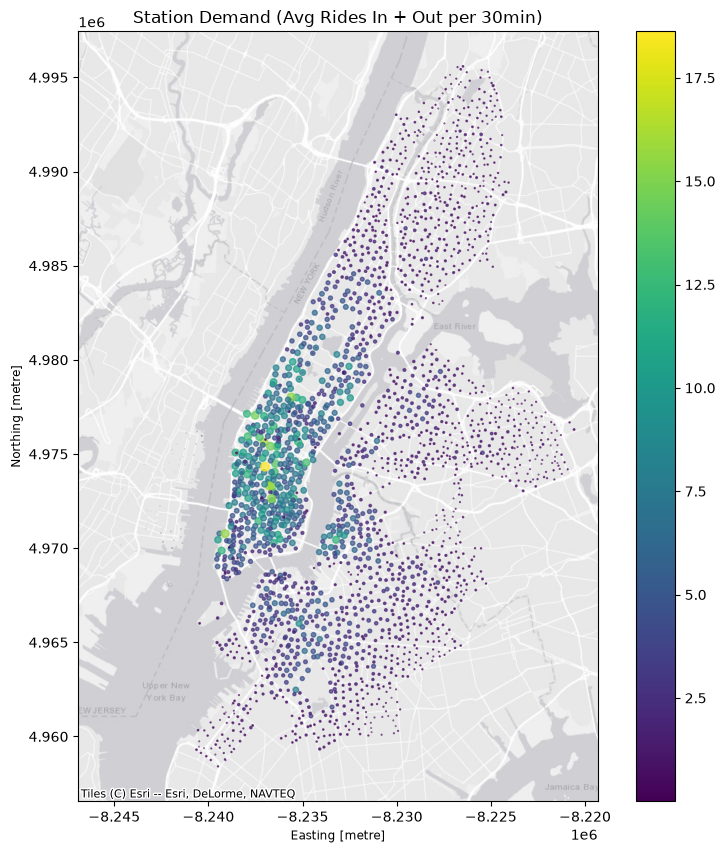

In [54]:
import contextily as ctx
stations_with_demand = station_stats.merge(stations_cord_df, how='left', on='station')

# Build GeoDataFrame
gdf = gpd.GeoDataFrame(
    stations_with_demand,
    geometry=gpd.points_from_xy(stations_with_demand["lon"], stations_with_demand["lat"]),
    crs="EPSG:4326"
).to_crs(epsg=3857)  # project to Web Mercator

# Plot with basemap
fig, ax = plt.subplots(figsize=(10,10))
gdf.plot(
    ax=ax,
    column="avg_rides_30min",
    cmap="viridis",
    markersize=gdf["avg_rides_30min"]*2,
    alpha=0.7,
    legend=True
)

ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)   # CartoDB tiles now require an API key
plt.title("Station Demand (Avg Rides In + Out per 30min)")
plt.savefig("figures/station_demand.png", dpi=200, bbox_inches="tight")
plt.show()


In [55]:
import folium
import branca.colormap as cm

stations_clean = stations_with_demand.dropna(subset=["lat", "lon"])

m = folium.Map(location=[40.73, -73.94], zoom_start=12, tiles="Esri.WorldGrayCanvas")

# Continuous Viridis colormap
colormap = cm.linear.viridis.scale(
    stations_clean["avg_rides_30min"].min(),
    stations_clean["avg_rides_30min"].max()
)

for _, row in stations_clean.iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=row["avg_rides_30min"] / 5,
        fill=True,
        fill_opacity=0.6,
        color=colormap(row["avg_rides_30min"]),
        fill_color=colormap(row["avg_rides_30min"]),
        popup=f"{row['station']}: {row['avg_rides_30min']:.1f} rides in + out per 30 min"
    ).add_to(m)

colormap.caption = "Avg Rides In + Out per 30min"
colormap.add_to(m)

m.save("station_demand_map.html")
print("Interactive map saved to station_demand_map.html (open it in a browser)")


Interactive map saved to station_demand_map.html (open it in a browser)


In [56]:

# Define window
event_date = "2024-11-08"
start_time = f"{event_date} 18:00:00"
end_time   = f"{event_date} 19:00:00"   # last 30-minute slot starts 19:00, so the window is 6:00-7:30 PM

# Filter arrivals within window and sum across time
event_arrivals = df_enter_final.loc[start_time:end_time].sum(axis=0).reset_index()
event_arrivals.columns = ["station", "rides"]


In [57]:
event_station_counts = event_arrivals.merge(stations_cord_df, on="station", how="left")

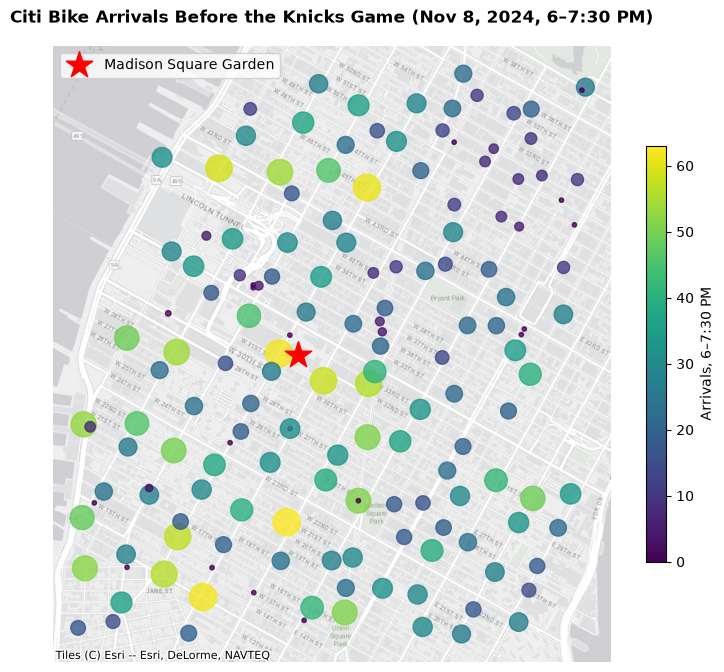

In [58]:
# Arrivals near Madison Square Garden in the 90 minutes before tip-off (a static map, so it also shows on GitHub)
MSG_LAT, MSG_LON = 40.7505, -73.9934
near_msg = event_station_counts.dropna(subset=["lat", "lon"])
# Stations in a box about 3.3 km across, centered on the Garden (±0.015° latitude, ±0.02° longitude)
near_msg = near_msg[((near_msg["lat"] - MSG_LAT).abs() < 0.015) & ((near_msg["lon"] - MSG_LON).abs() < 0.02)]

event_gdf = gpd.GeoDataFrame(
    near_msg, geometry=gpd.points_from_xy(near_msg["lon"], near_msg["lat"]), crs="EPSG:4326"
).to_crs(epsg=3857)
msg_point = gpd.GeoSeries(gpd.points_from_xy([MSG_LON], [MSG_LAT]), crs="EPSG:4326").to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(9, 9))
event_gdf.plot(
    ax=ax,
    column="rides",
    cmap="viridis",
    markersize=10 + event_gdf["rides"] * 6,
    alpha=0.8,
    legend=True,
    legend_kwds={"label": "Arrivals, 6–7:30 PM", "shrink": 0.6}
)
msg_point.plot(ax=ax, marker="*", color="red", markersize=400, label="Madison Square Garden")
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
ax.set_title("Citi Bike Arrivals Before the Knicks Game (Nov 8, 2024, 6–7:30 PM)", fontweight="bold")
ax.legend(loc="upper left")
ax.set_axis_off()
plt.show()

In [59]:
# Was game night unusual? Arrivals at the same stations, 6:00-7:30 PM, on every Friday in October-November 2024
fridays = pd.date_range("2024-10-04", "2024-11-29", freq="W-FRI")
friday_arrivals = pd.Series(
    [df_enter_final.loc[f"{day:%Y-%m-%d} 18:00:00":f"{day:%Y-%m-%d} 19:00:00", near_msg["station"]].sum().sum() for day in fridays],
    index=fridays.strftime("%a %b %d"),
    name="arrivals 6-7:30 PM",
)
print(f"{len(near_msg)} stations in a box about 3.3 km across, centered on Madison Square Garden")
friday_arrivals.to_frame()

158 stations in a box about 3.3 km across, centered on Madison Square Garden


,arrivals 6-7:30 PM
Fri Oct 04,4413
Fri Oct 11,3998
Fri Oct 18,4041
Fri Oct 25,4271
Fri Nov 01,4646
Fri Nov 08,3900
Fri Nov 15,3297
Fri Nov 22,747
Fri Nov 29,1206


**Game night doesn't stand out.** Arrivals near the Garden on Nov 8 (about 3,900) were within the range of the other Friday evenings from October 4 to November 15 (about 3,300–4,600). Only Nov 22 and Nov 29 (the day after Thanksgiving) were much lower. This comparison does not show a clear game-night increase.